# Dermatomyositis Xenium 5K — shared skin niches and inflammatory aggregates

**1张健康 H8（5k_H3）＋1张皮肌炎 DM21（5k_DM6）**。选择 `cccphe`，Restart Kernel → Run All；配置一致的完整结果直接复用。

依据[原文 Fig. 3 和 Methods](https://www.nature.com/articles/s41467-026-74871-7)及其公开源数据选片：DM21 有8个作者定义的 Dermis_Disease 聚集区，最大区 `total_cells=1,405`，并具有较完整的组织形状和较好检测深度。H8 在3个健康切片中粗粒度组成更均衡，成纤维细胞31.2%、表皮细胞30.2%。作者的聚集区/精细注释用于选片与解释，不作为模型训练或 K 选择标签。[原始数据](https://zenodo.org/records/20386623)。

完整保留组织共同训练：表达＋空间图 → 32维非负 Z → ZH；NMF初始化，CCC Huber重构＋0.005程序正则。不输入细胞类型，不训练组成或调控分支。根据 H 定义的相对 CCC 谱距离及弱总活性，无监督选择 K=4–15；训练子集只用于监测。

整片总图展示全部保留细胞；细胞状态图参照原文，用灰色衬托其余细胞，揭示粗分类掩盖的免疫/间质结构。所有大文件和旧实验保留在 NAS。本例是一对切片的描述性比较。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json,contextlib
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina')
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.cohorts.dermatomyositis import run
from phenoniche.cohorts.dermatomyositis_reporting import DermatomyositisReport
CONFIG=ROOT/'config/dermatomyositis_5k.json'
OUTPUT=Path(json.loads(CONFIG.read_text())['output_dir'])
OUTPUT.mkdir(parents=True,exist_ok=True)
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    run(CONFIG)
report=DermatomyositisReport(OUTPUT)
def show(fig):
    display(fig);plt.close(fig)
display(report.overview())

,condition,patient,image,cells,median_counts,median_genes,inflammation_local_p90,retained_cells,author_Dermis_Disease_aggregates,author_largest_Dermis_Disease_cells
0,DM,patient_DM21,5k_DM6,13308,677.0,433.0,1.116319,13300,8,1405
1,HC,patient_H8,5k_H3,24406,374.0,273.0,0.074561,24225,0,0


## 1. 完整切片：细胞类型与联合发现的 niches

每列使用同一切片全部保留细胞和原始坐标；保持真实形状及µm比例。细胞类型用于CCC监督及解释，不输入编码器。

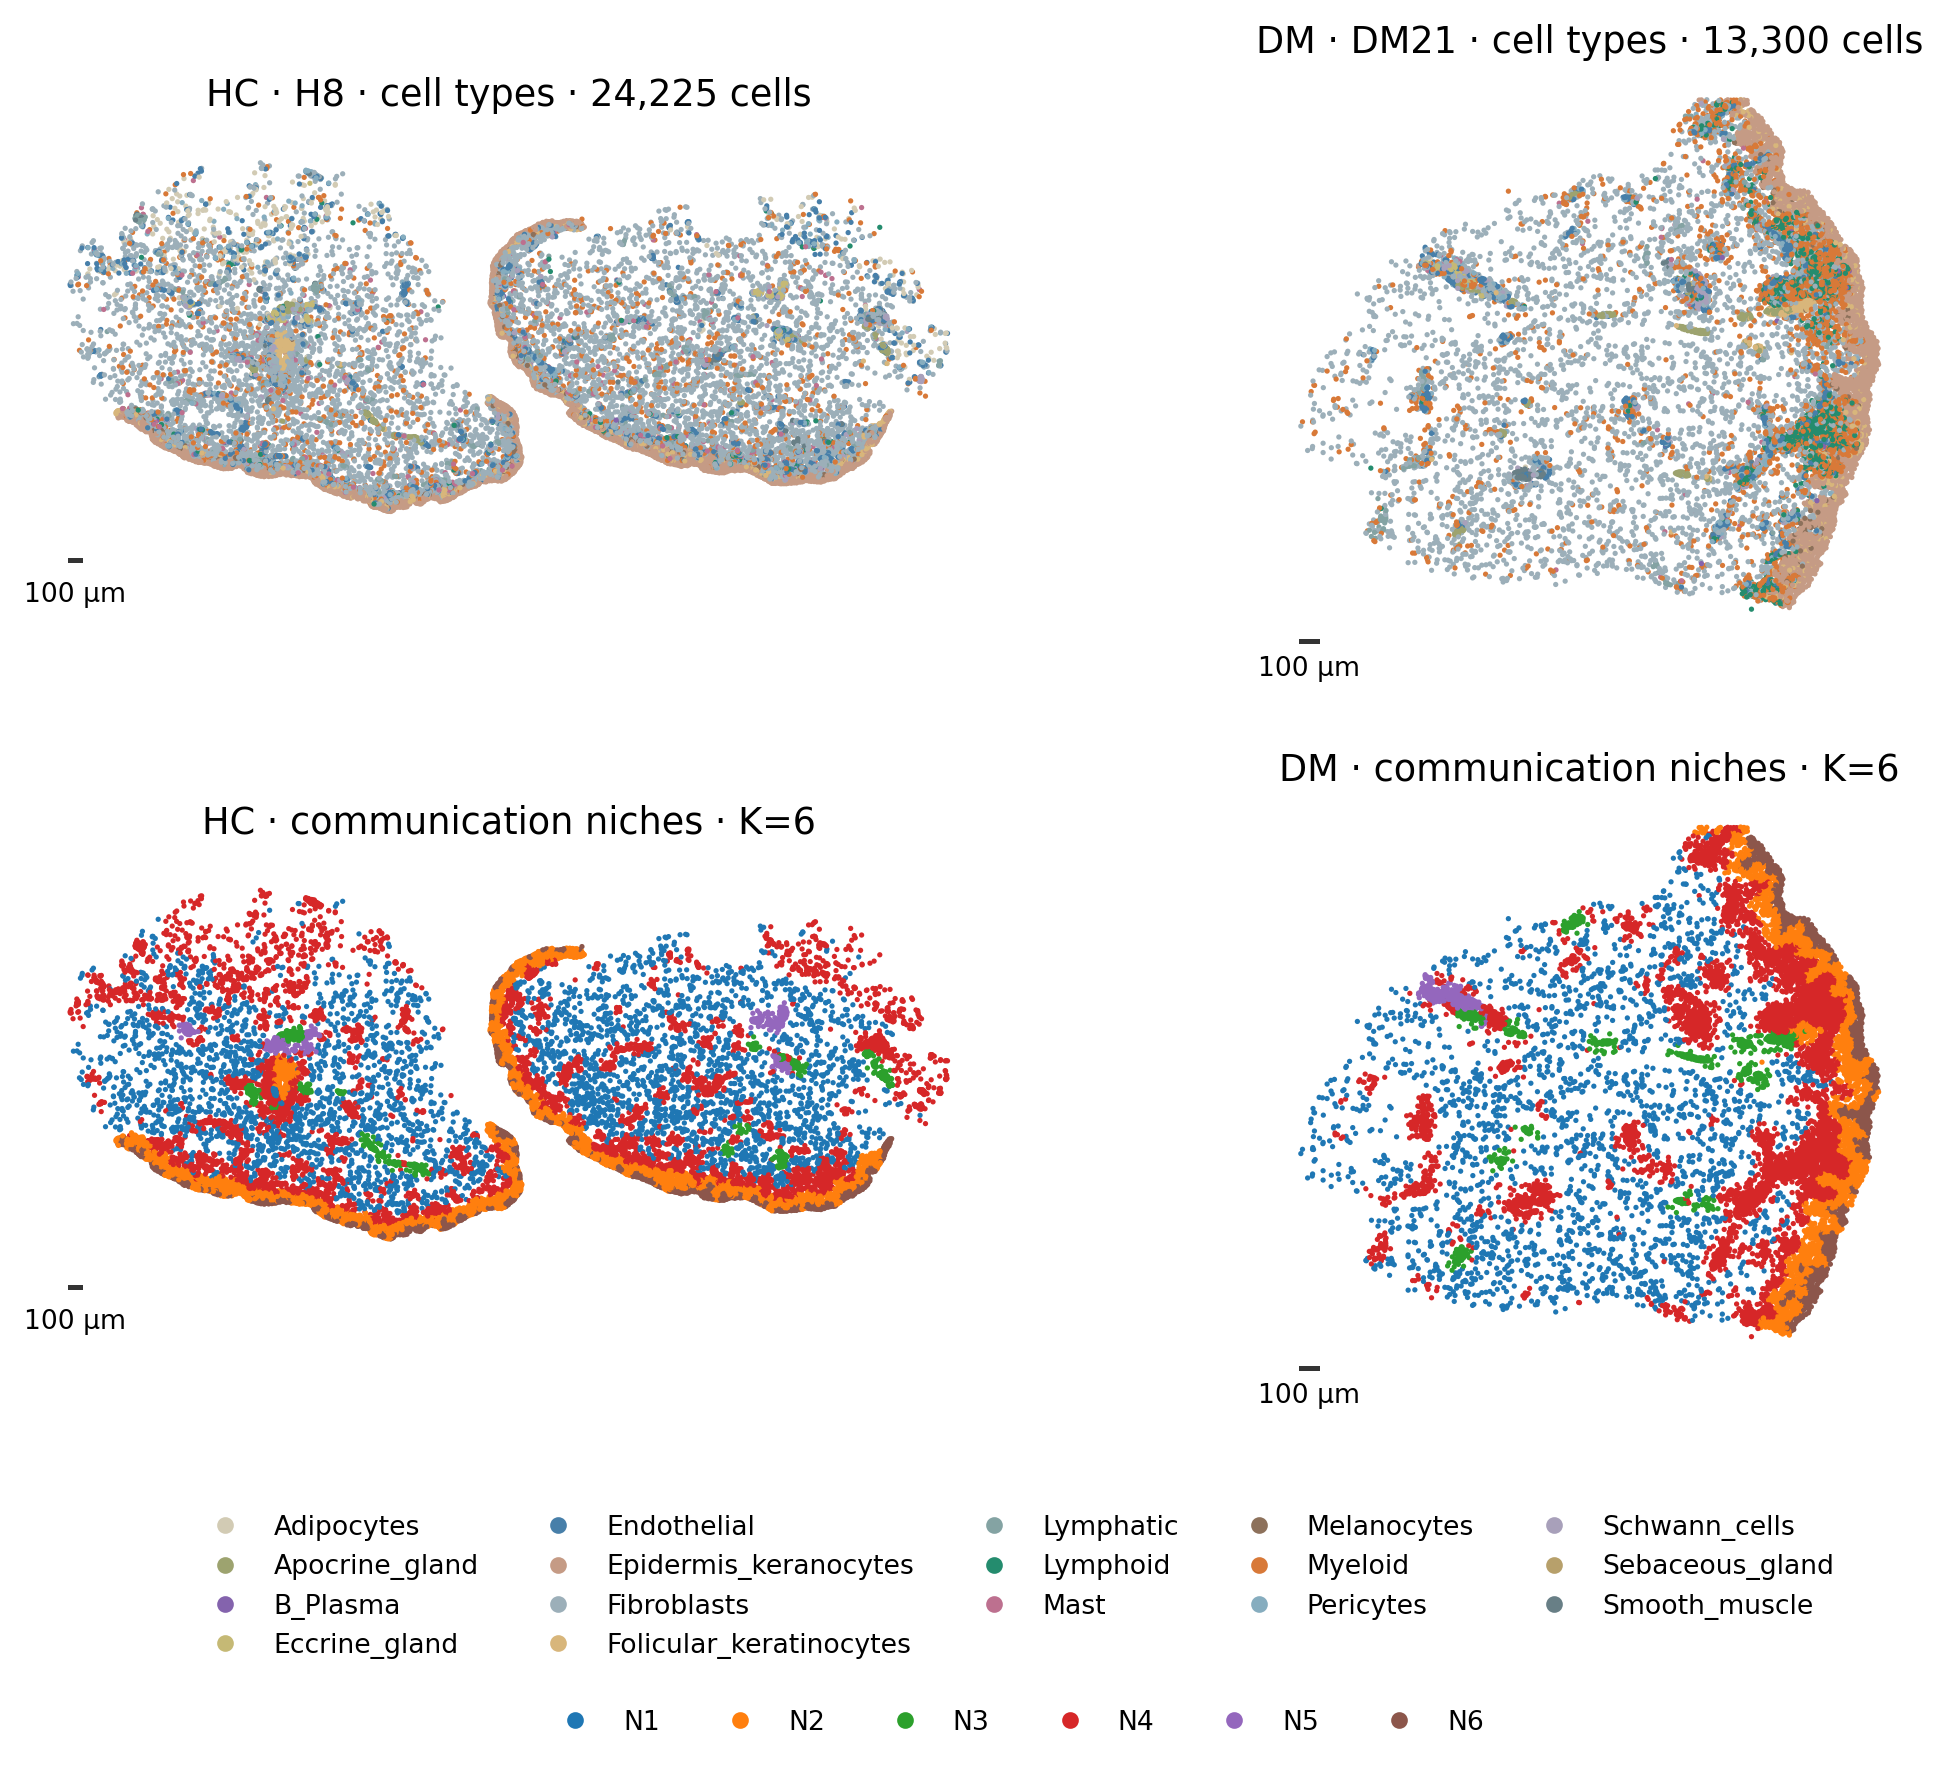

In [2]:
show(report.spatial())

## 2. 原文关注的结构：间质状态与免疫聚集区

左：作者的成纤维细胞状态；中：精细免疫细胞状态；右：免疫空间权重≥20%的微环境对应的 **GNN niche**。灰色是其余细胞/微环境，未删除，不改变训练或聚类。三列保持相同位置；右侧阈值仅用于显示，不等同于原文的HDBSCAN聚集区，也不把作者的疾病niche作为真值。

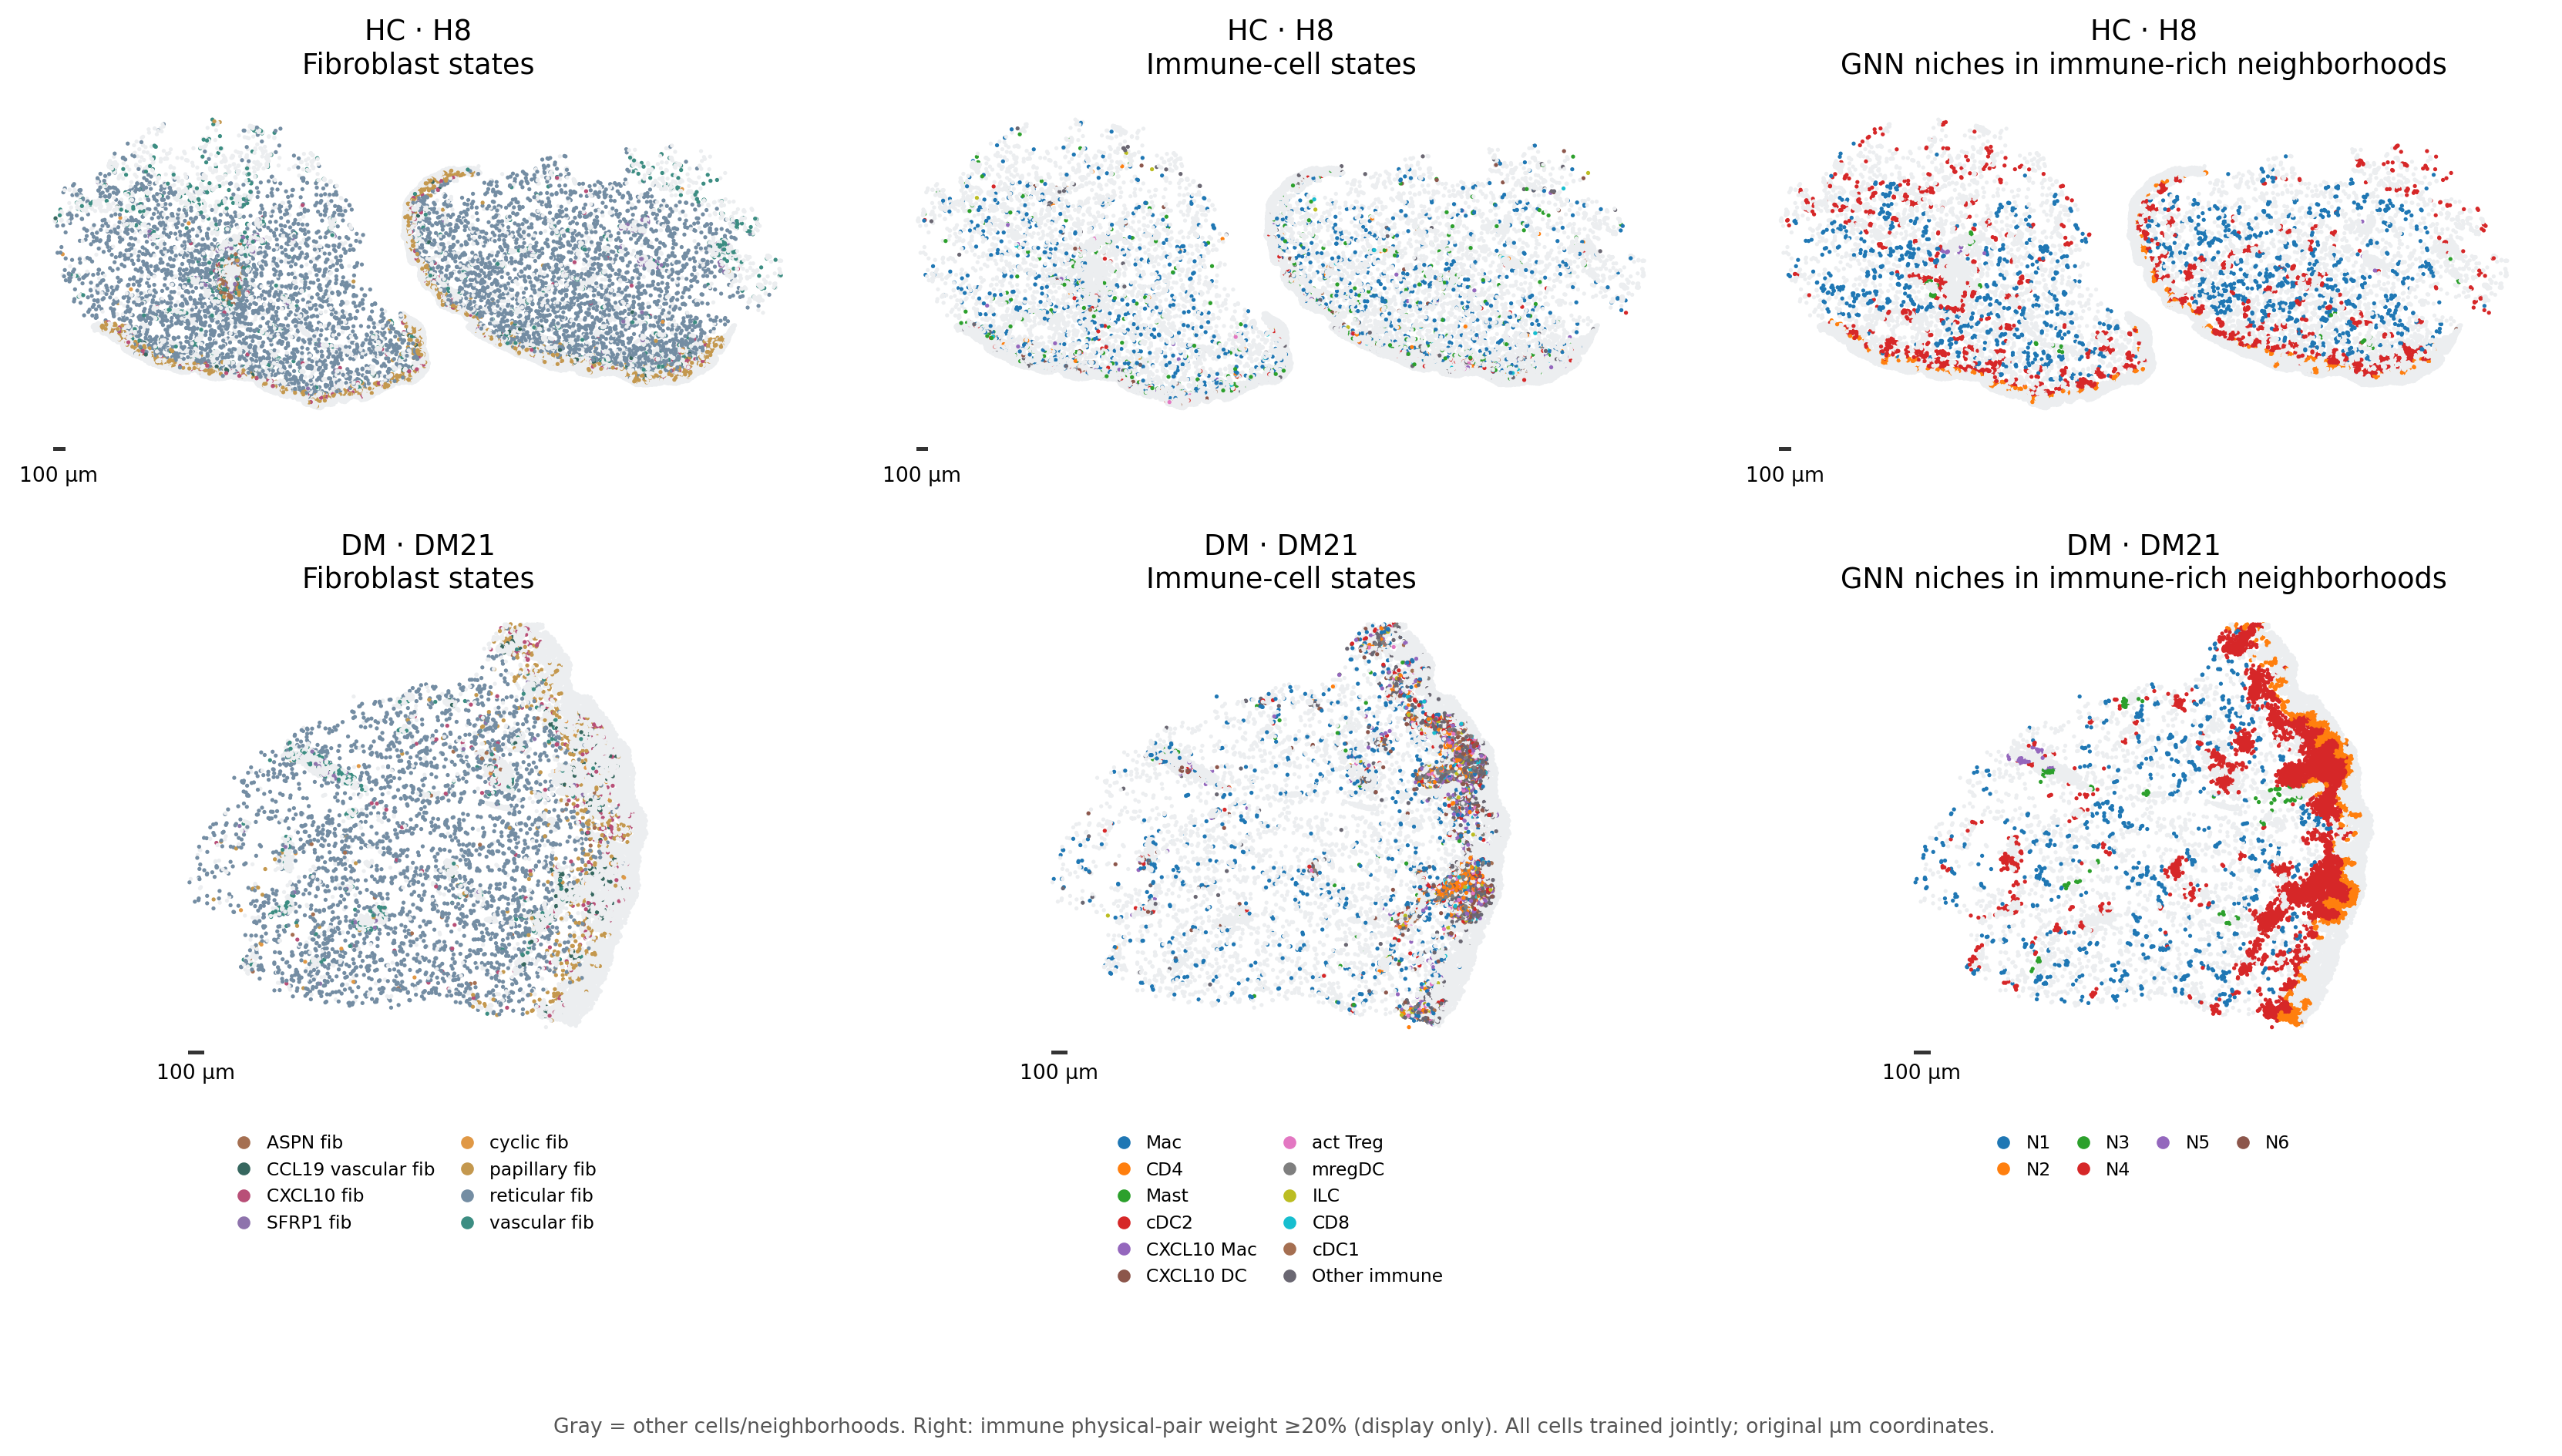

In [3]:
show(report.paper_context())

## 3. 哪些 niche 在病例中增加？

上：全部 niche 的两片占比与差值。下：突出病例中增加、且具有免疫组成的一个 niche（按增加幅度×空间加权免疫比例选择，仅用于结果解释）。完整组织全部保留。

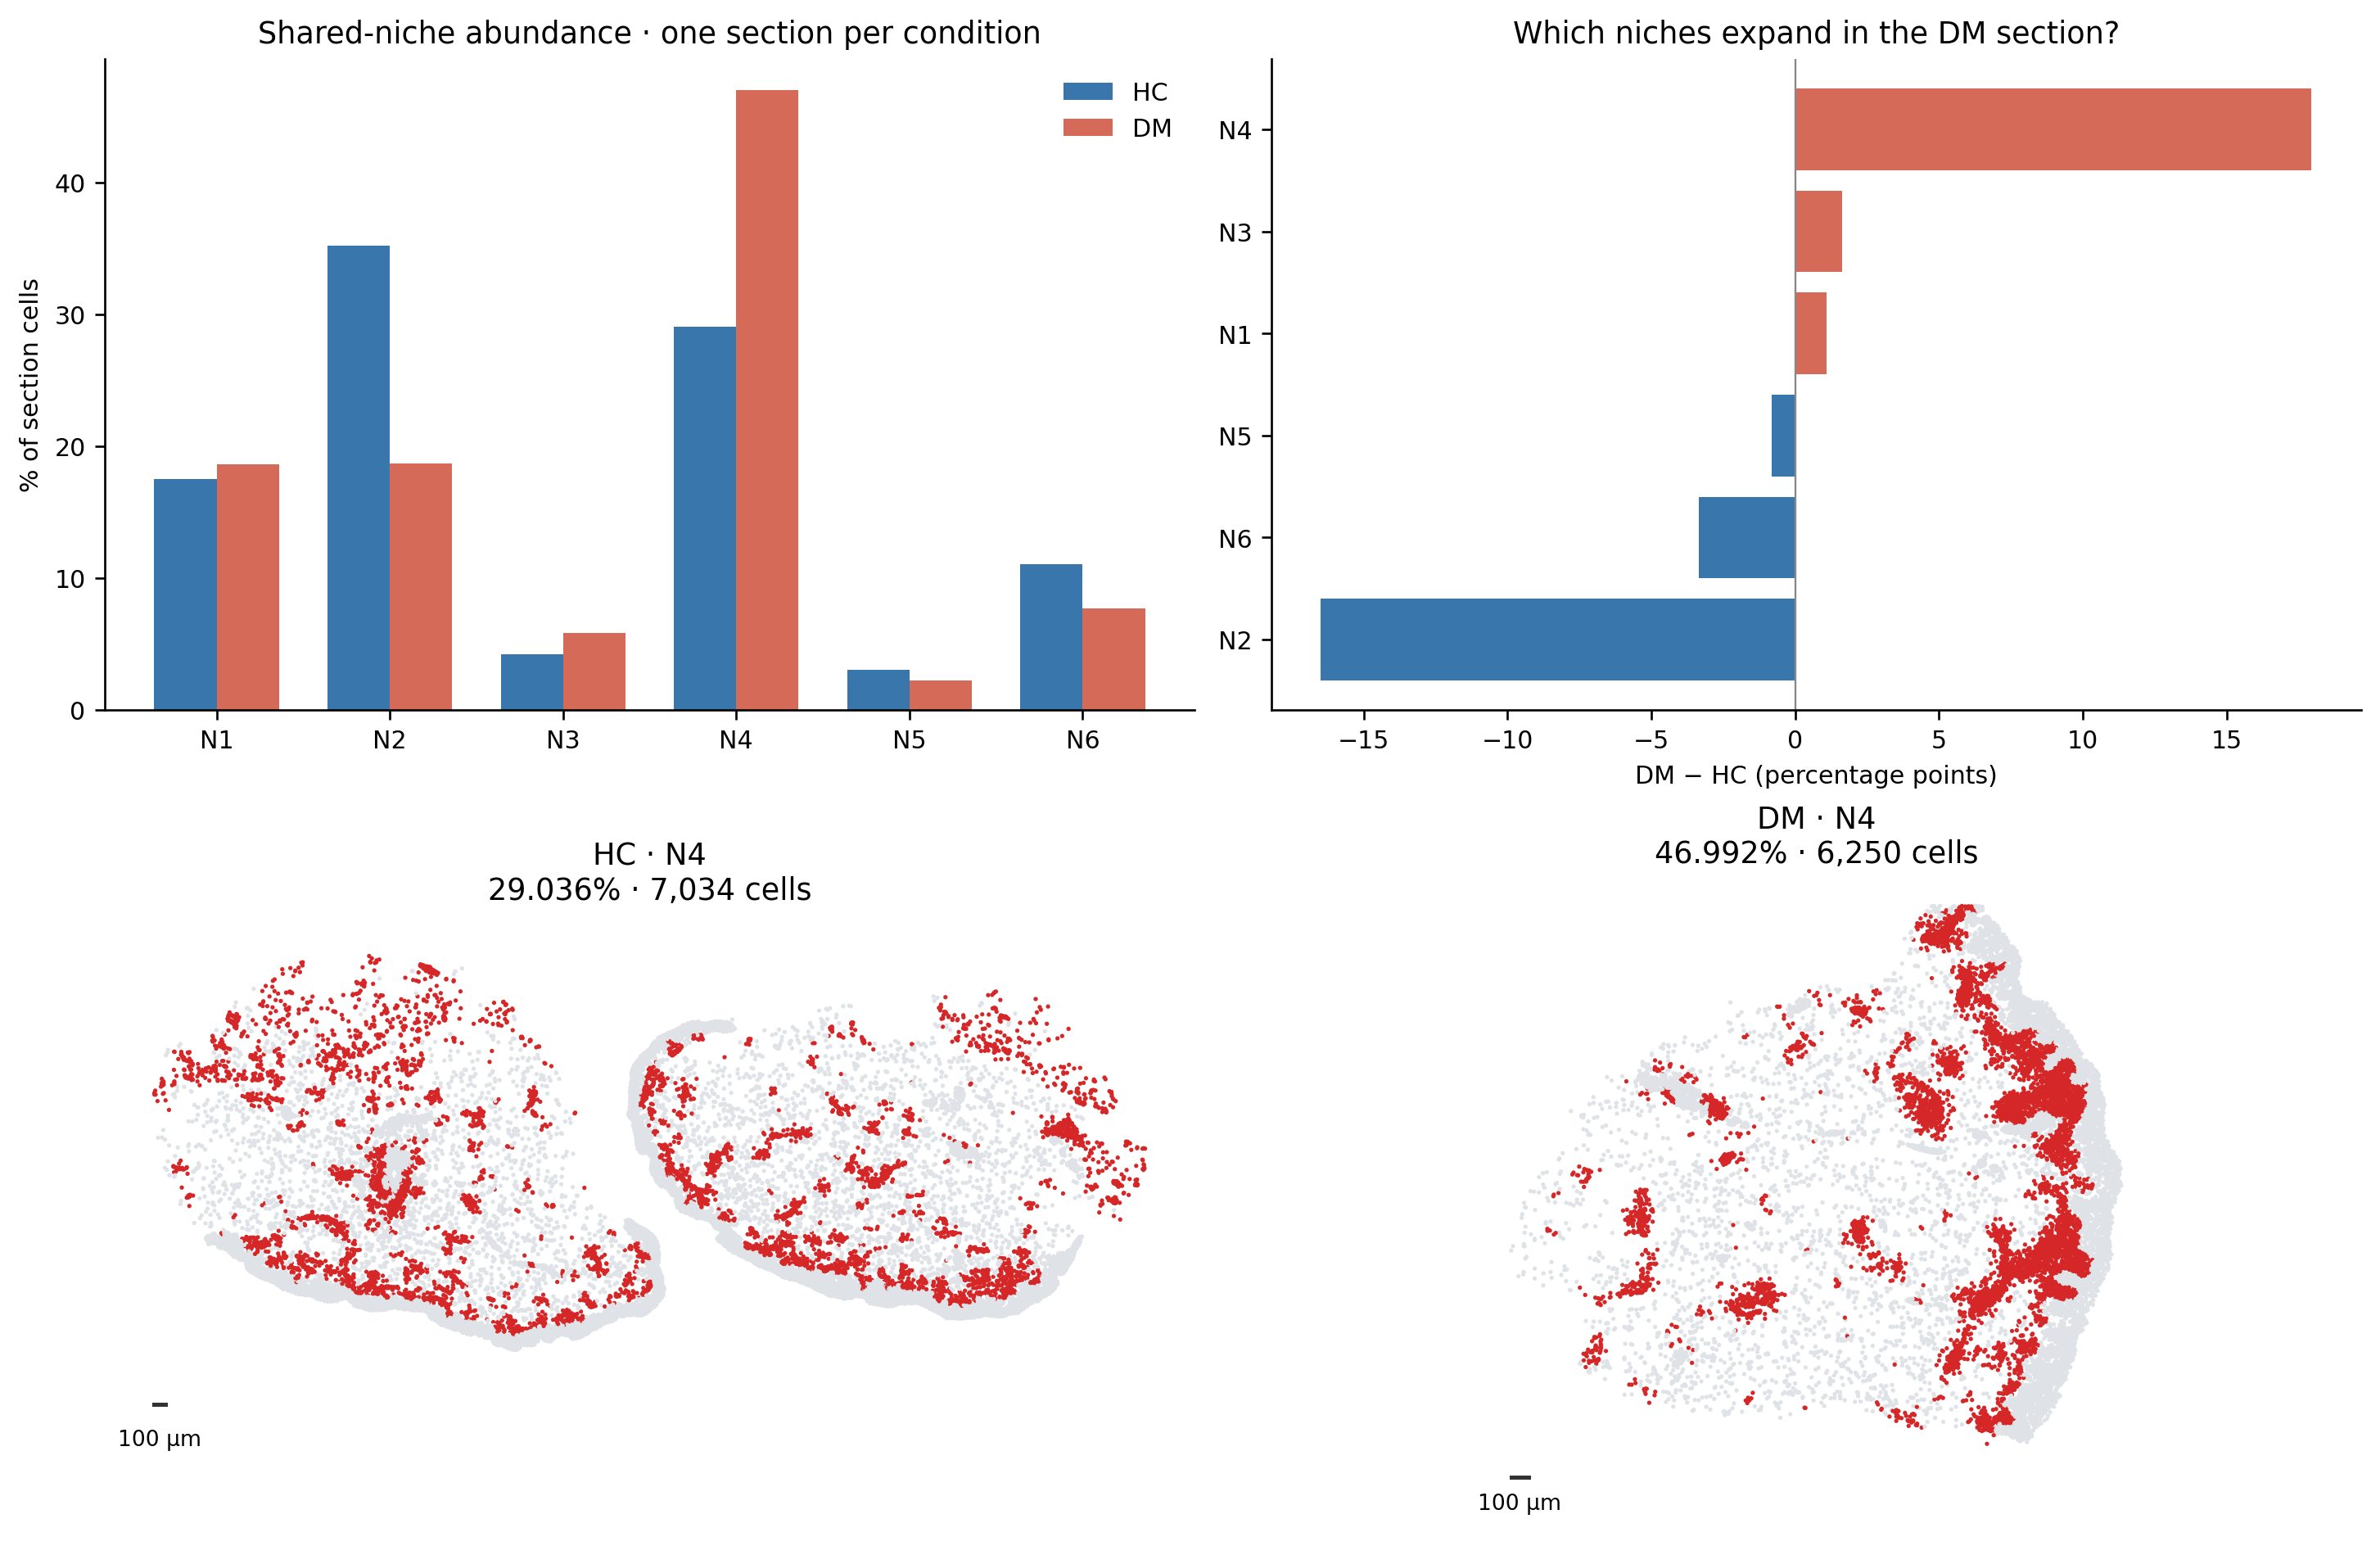

In [4]:
show(report.abundance())

## 4. Niche 的程序、组成与代表性 CCC

左：niche × 通讯程序；右：原物理细胞对权重计算的组成。下表展示病例增加幅度×免疫比例排名靠前的两个 niche 的 top10 sender→receiver→LR；所有 niche 的完整表均保存于 NAS。

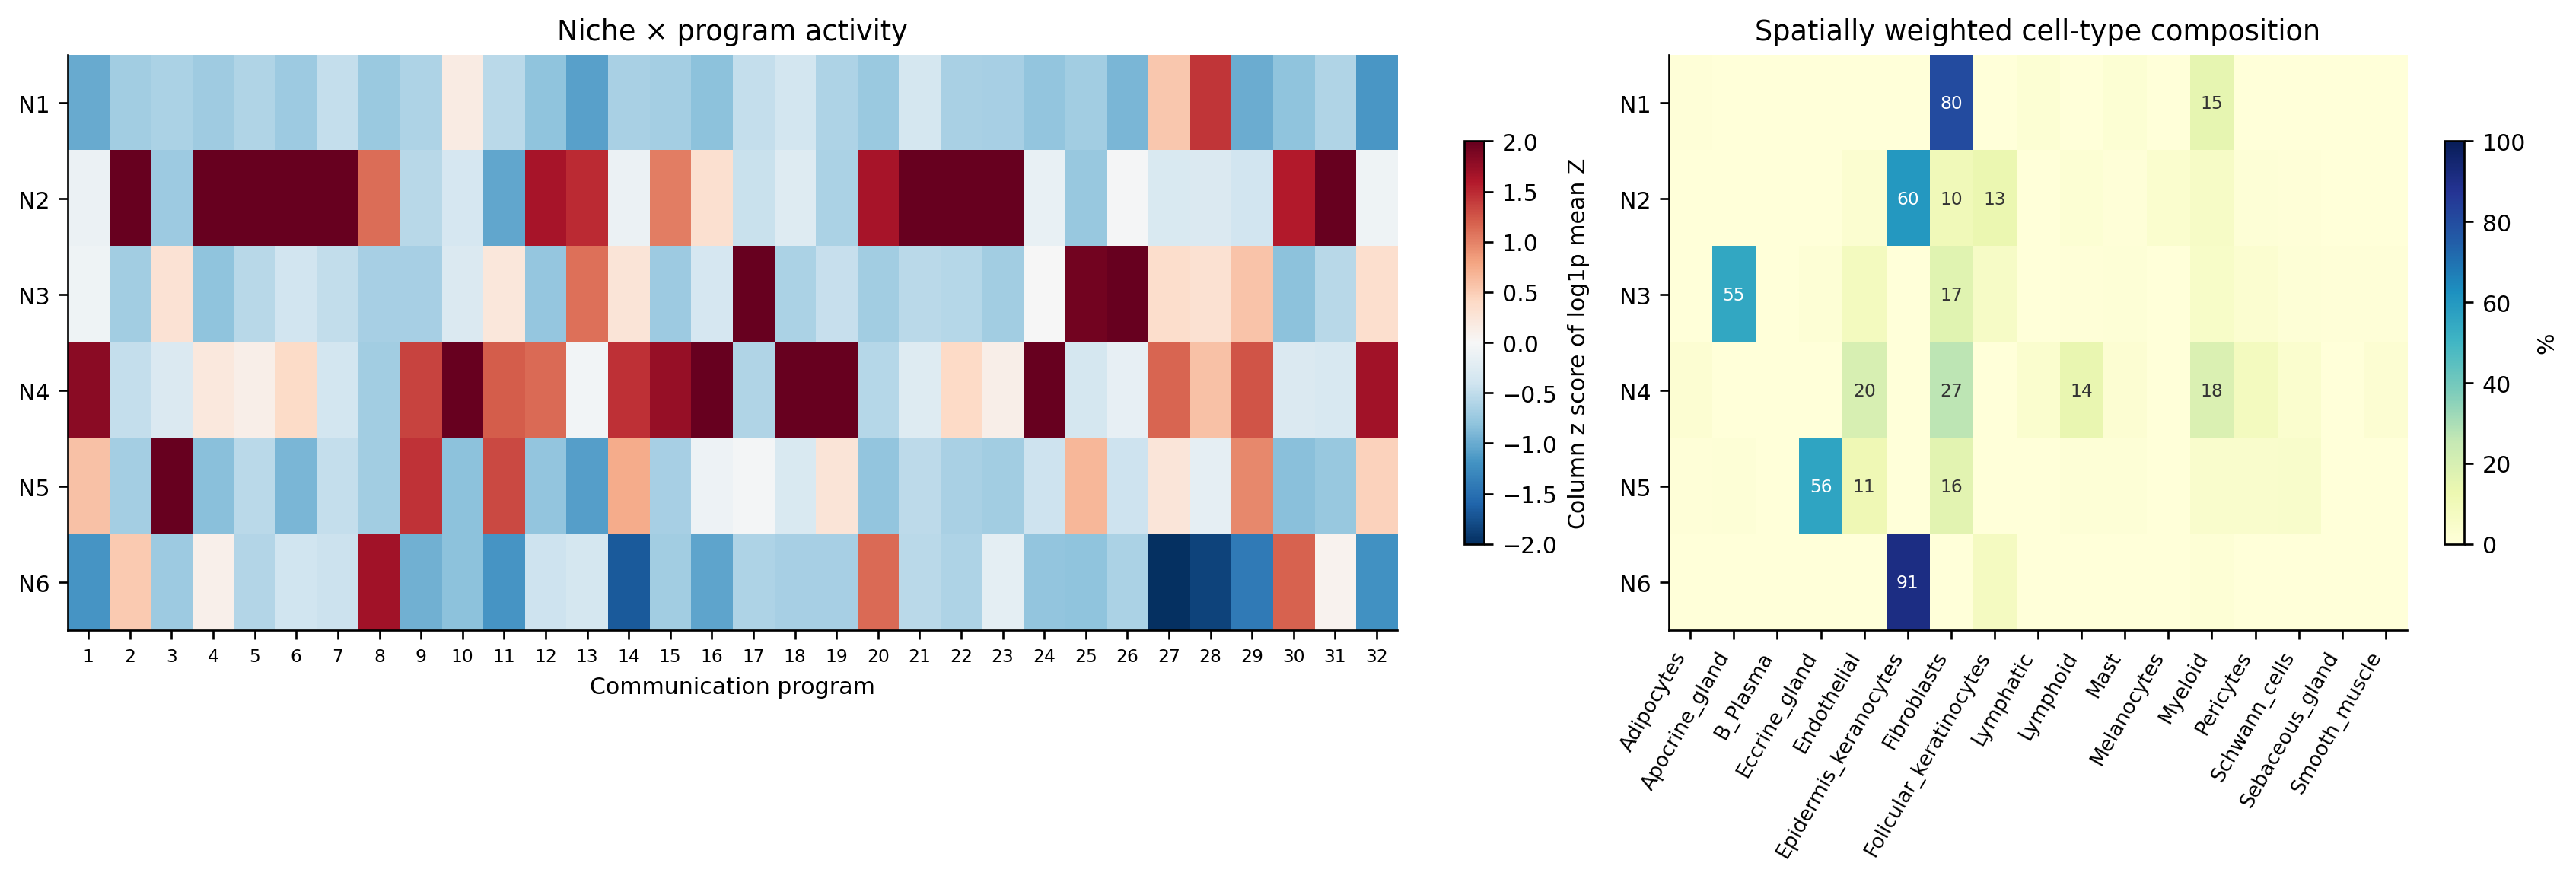

,niche,rank,sender,receiver,LR,mean_reconstructed_CCC,main_program
0,1,1,Fibroblasts,Fibroblasts,MMP14–MMP2,3.936,28
1,1,2,Fibroblasts,Fibroblasts,COL6A1–CD44,2.301,28
2,1,3,Fibroblasts,Fibroblasts,TIMP2–MMP2,1.989,28
3,1,4,Fibroblasts,Fibroblasts,MMP2–FGFR1,1.688,28
4,1,5,Fibroblasts,Myeloid,APP–CD74,1.445,28
5,1,6,Fibroblasts,Fibroblasts,MMP14–CD44,1.231,28
6,1,7,Fibroblasts,Fibroblasts,SPARC–FGFR1,1.226,28
7,1,8,Fibroblasts,Fibroblasts,MMP2–SDC2,1.046,28
8,1,9,Fibroblasts,Fibroblasts,VCAN–CD44,0.836,28
9,1,10,Fibroblasts,Fibroblasts,CD99–CD99,0.745,28


In [5]:
show(report.niche_heatmaps())
display(report.tables())

## 5. 对比：增加“病例新增 niche”步骤

保持同一 GNN、Z/H 不变。健康切片按空间块分为背景与校准集，清除共享物理邻域；在组成相近的健康微环境中计算通讯距离，以健康95%分位阈值和局部空间支持识别候选。两张切片应用同一规则，候选共同无监督聚类为 R1…；不强行产生病例独有标签。

校准使用未做邻域平滑的表示，空间支持在阈值判定后计算，避免平滑重新引入共享邻域。该步骤不参与编码器训练或联合 K 选择。

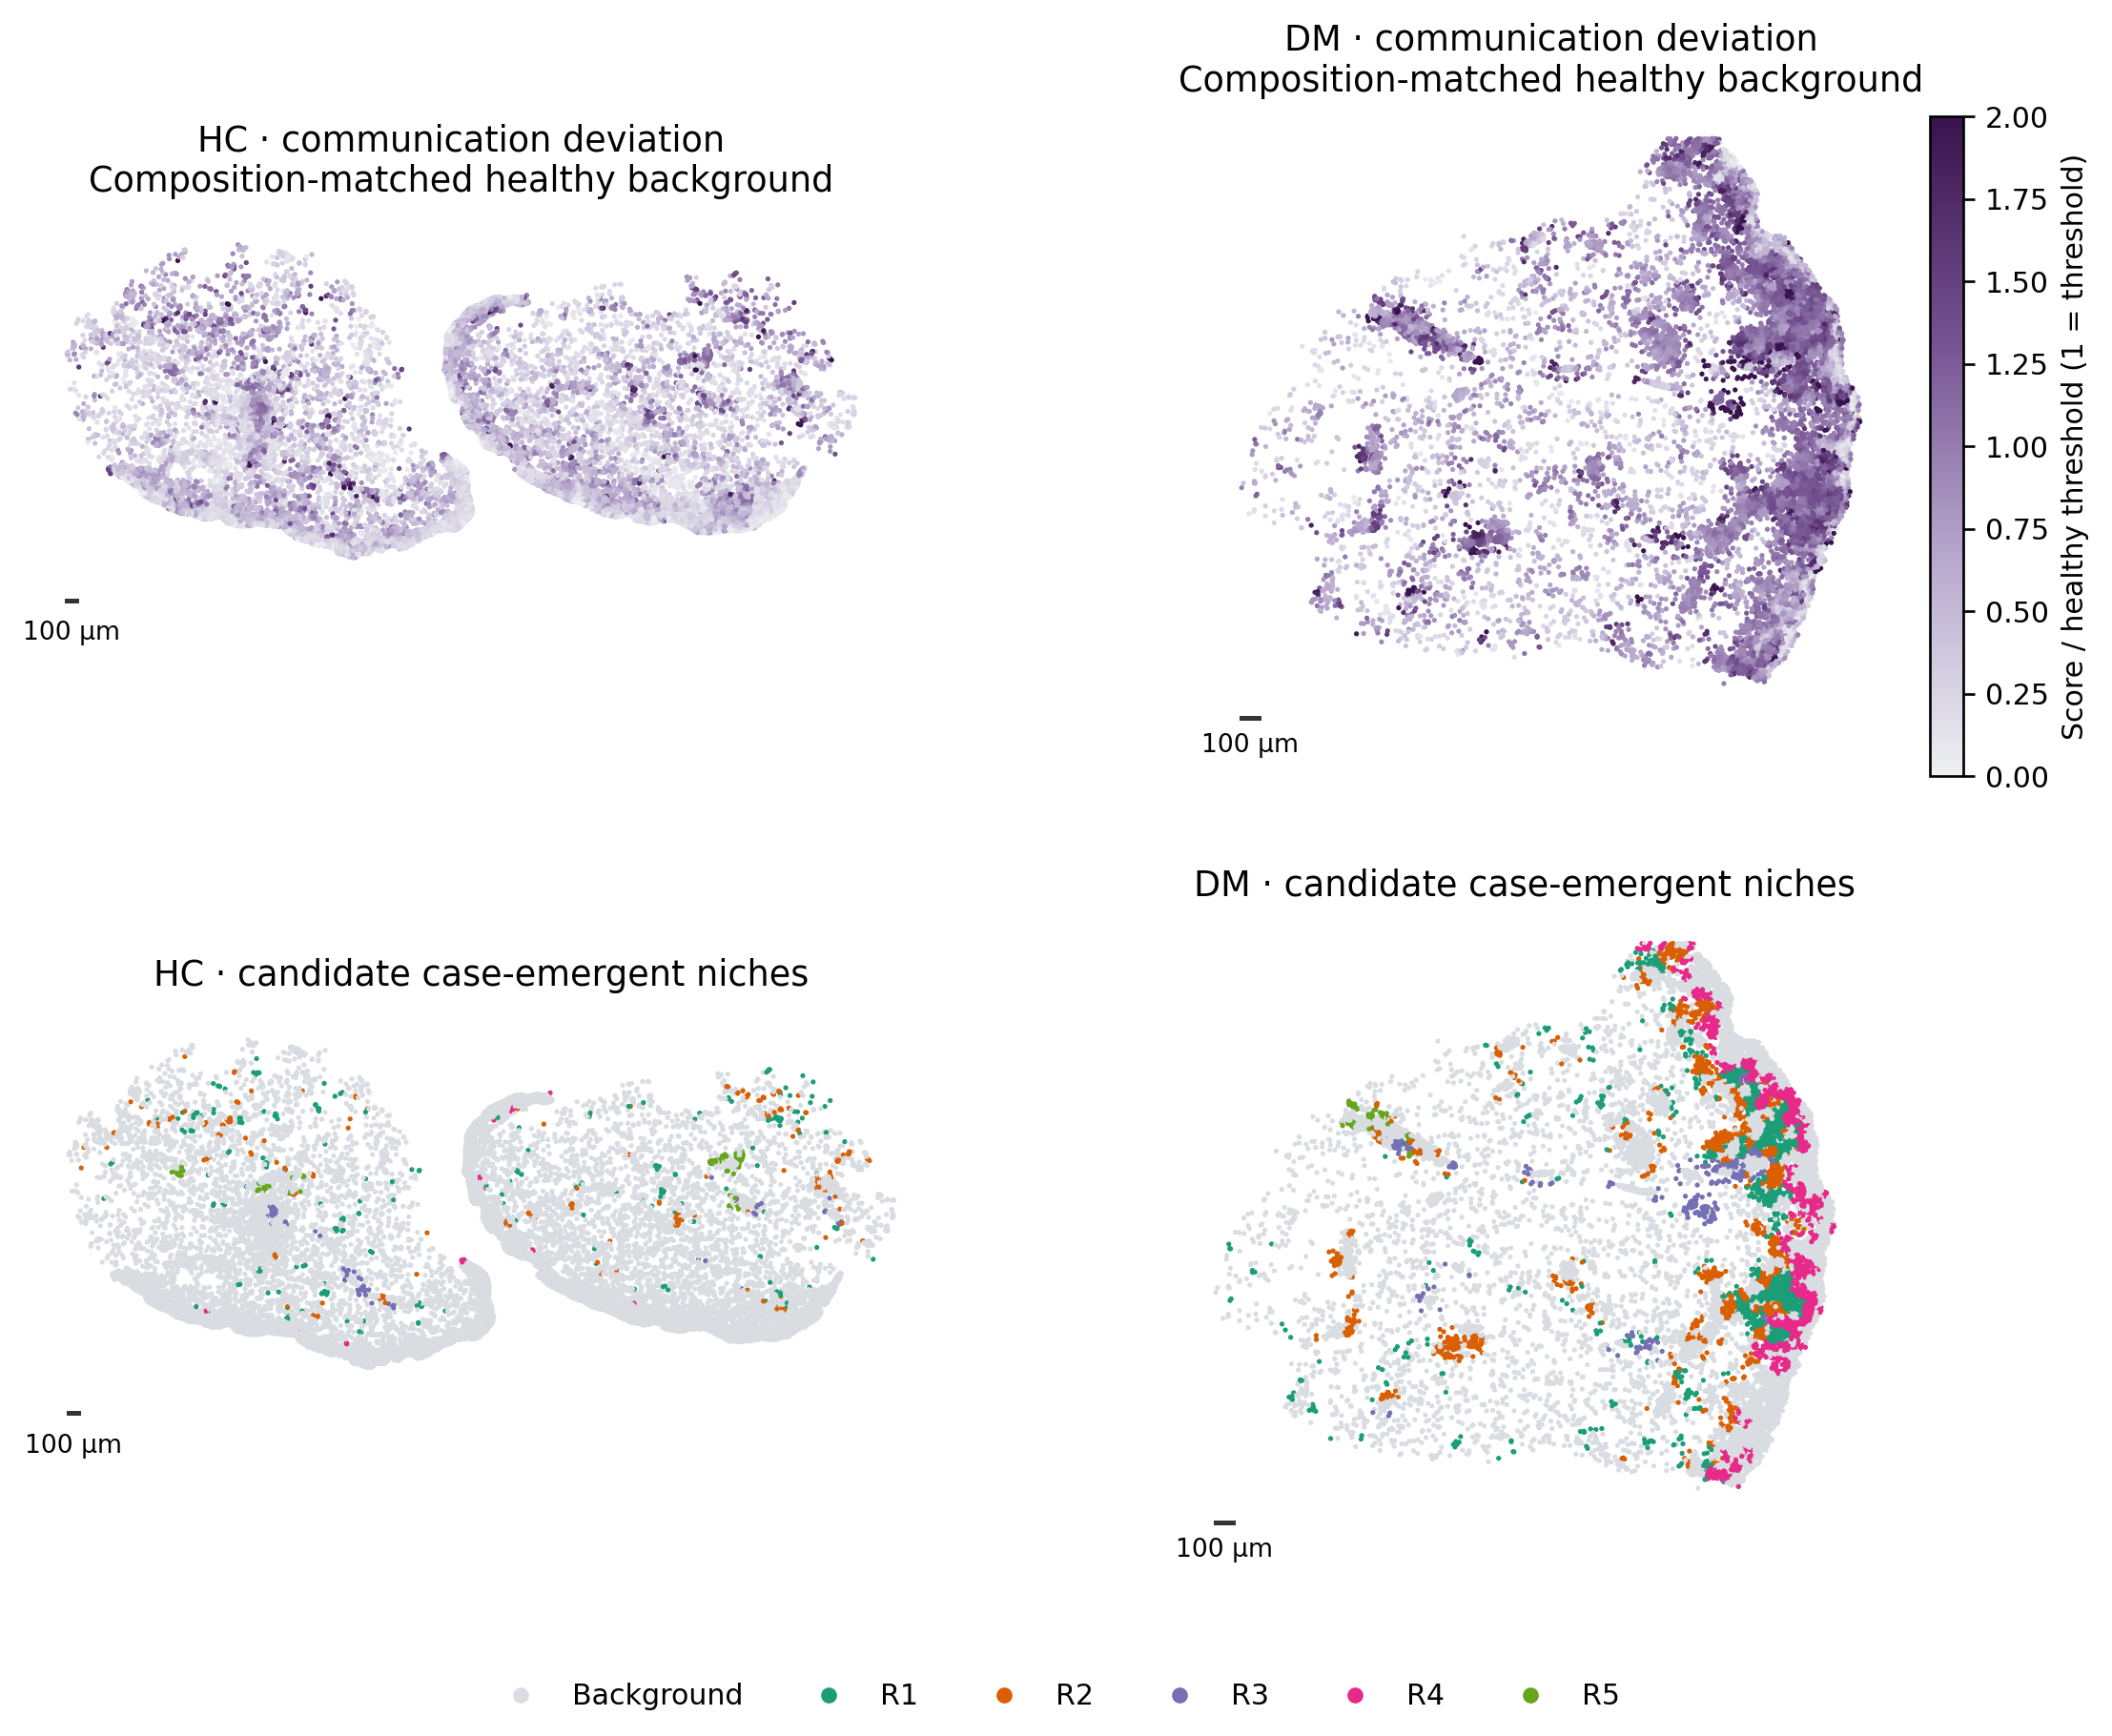

,candidate_niche,HC_fraction,DM_fraction,log2_DM_vs_HC,cells,DM_enriched
0,R1,0.010,0.116,3.346,1794,True
1,R2,0.012,0.122,3.219,1914,True
2,R3,0.010,0.028,1.400,617,True
3,R4,0.001,0.096,5.390,1313,True
4,R5,0.009,0.005,-0.739,291,False


Candidate top10 CCC: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/dermatomyositis_paper_guided/H8_DM21/case_novelty/top10_CCC.csv


In [6]:
show(report.novelty())
if len(report.candidates):
    display(report.candidates.round(3))
else:
    print('No spatially supported novel niche passed the prespecified threshold.')
print('Candidate top10 CCC:',OUTPUT/'case_novelty/top10_CCC.csv')

## 6. 训练过程与 CCC 重构

监测点属于训练切片；联合 K=4–15 选择不使用健康/疾病标签。

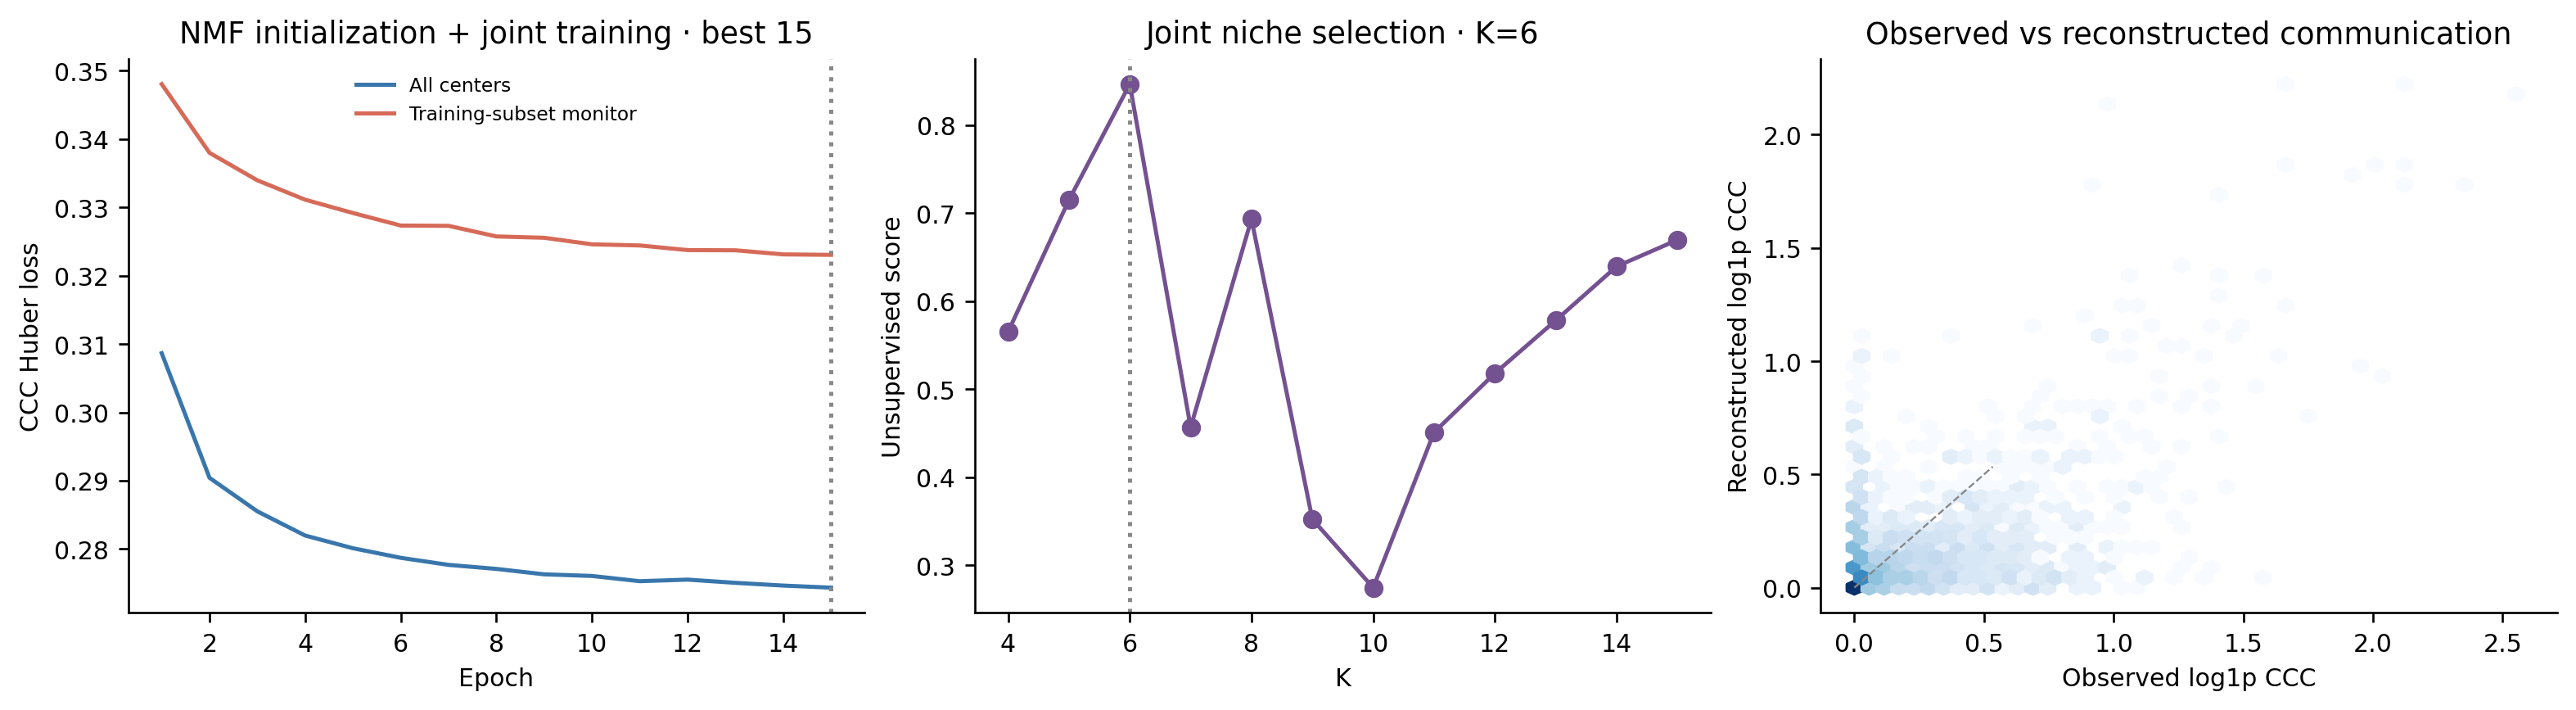

In [7]:
show(report.training())

## 7. 总图：共有组织背景与病例新增区域

相同细胞、同一模型，比较联合 niche 与可选新增分析。原有 H7/DM19、H8/DM27 及更早结果全部保留。

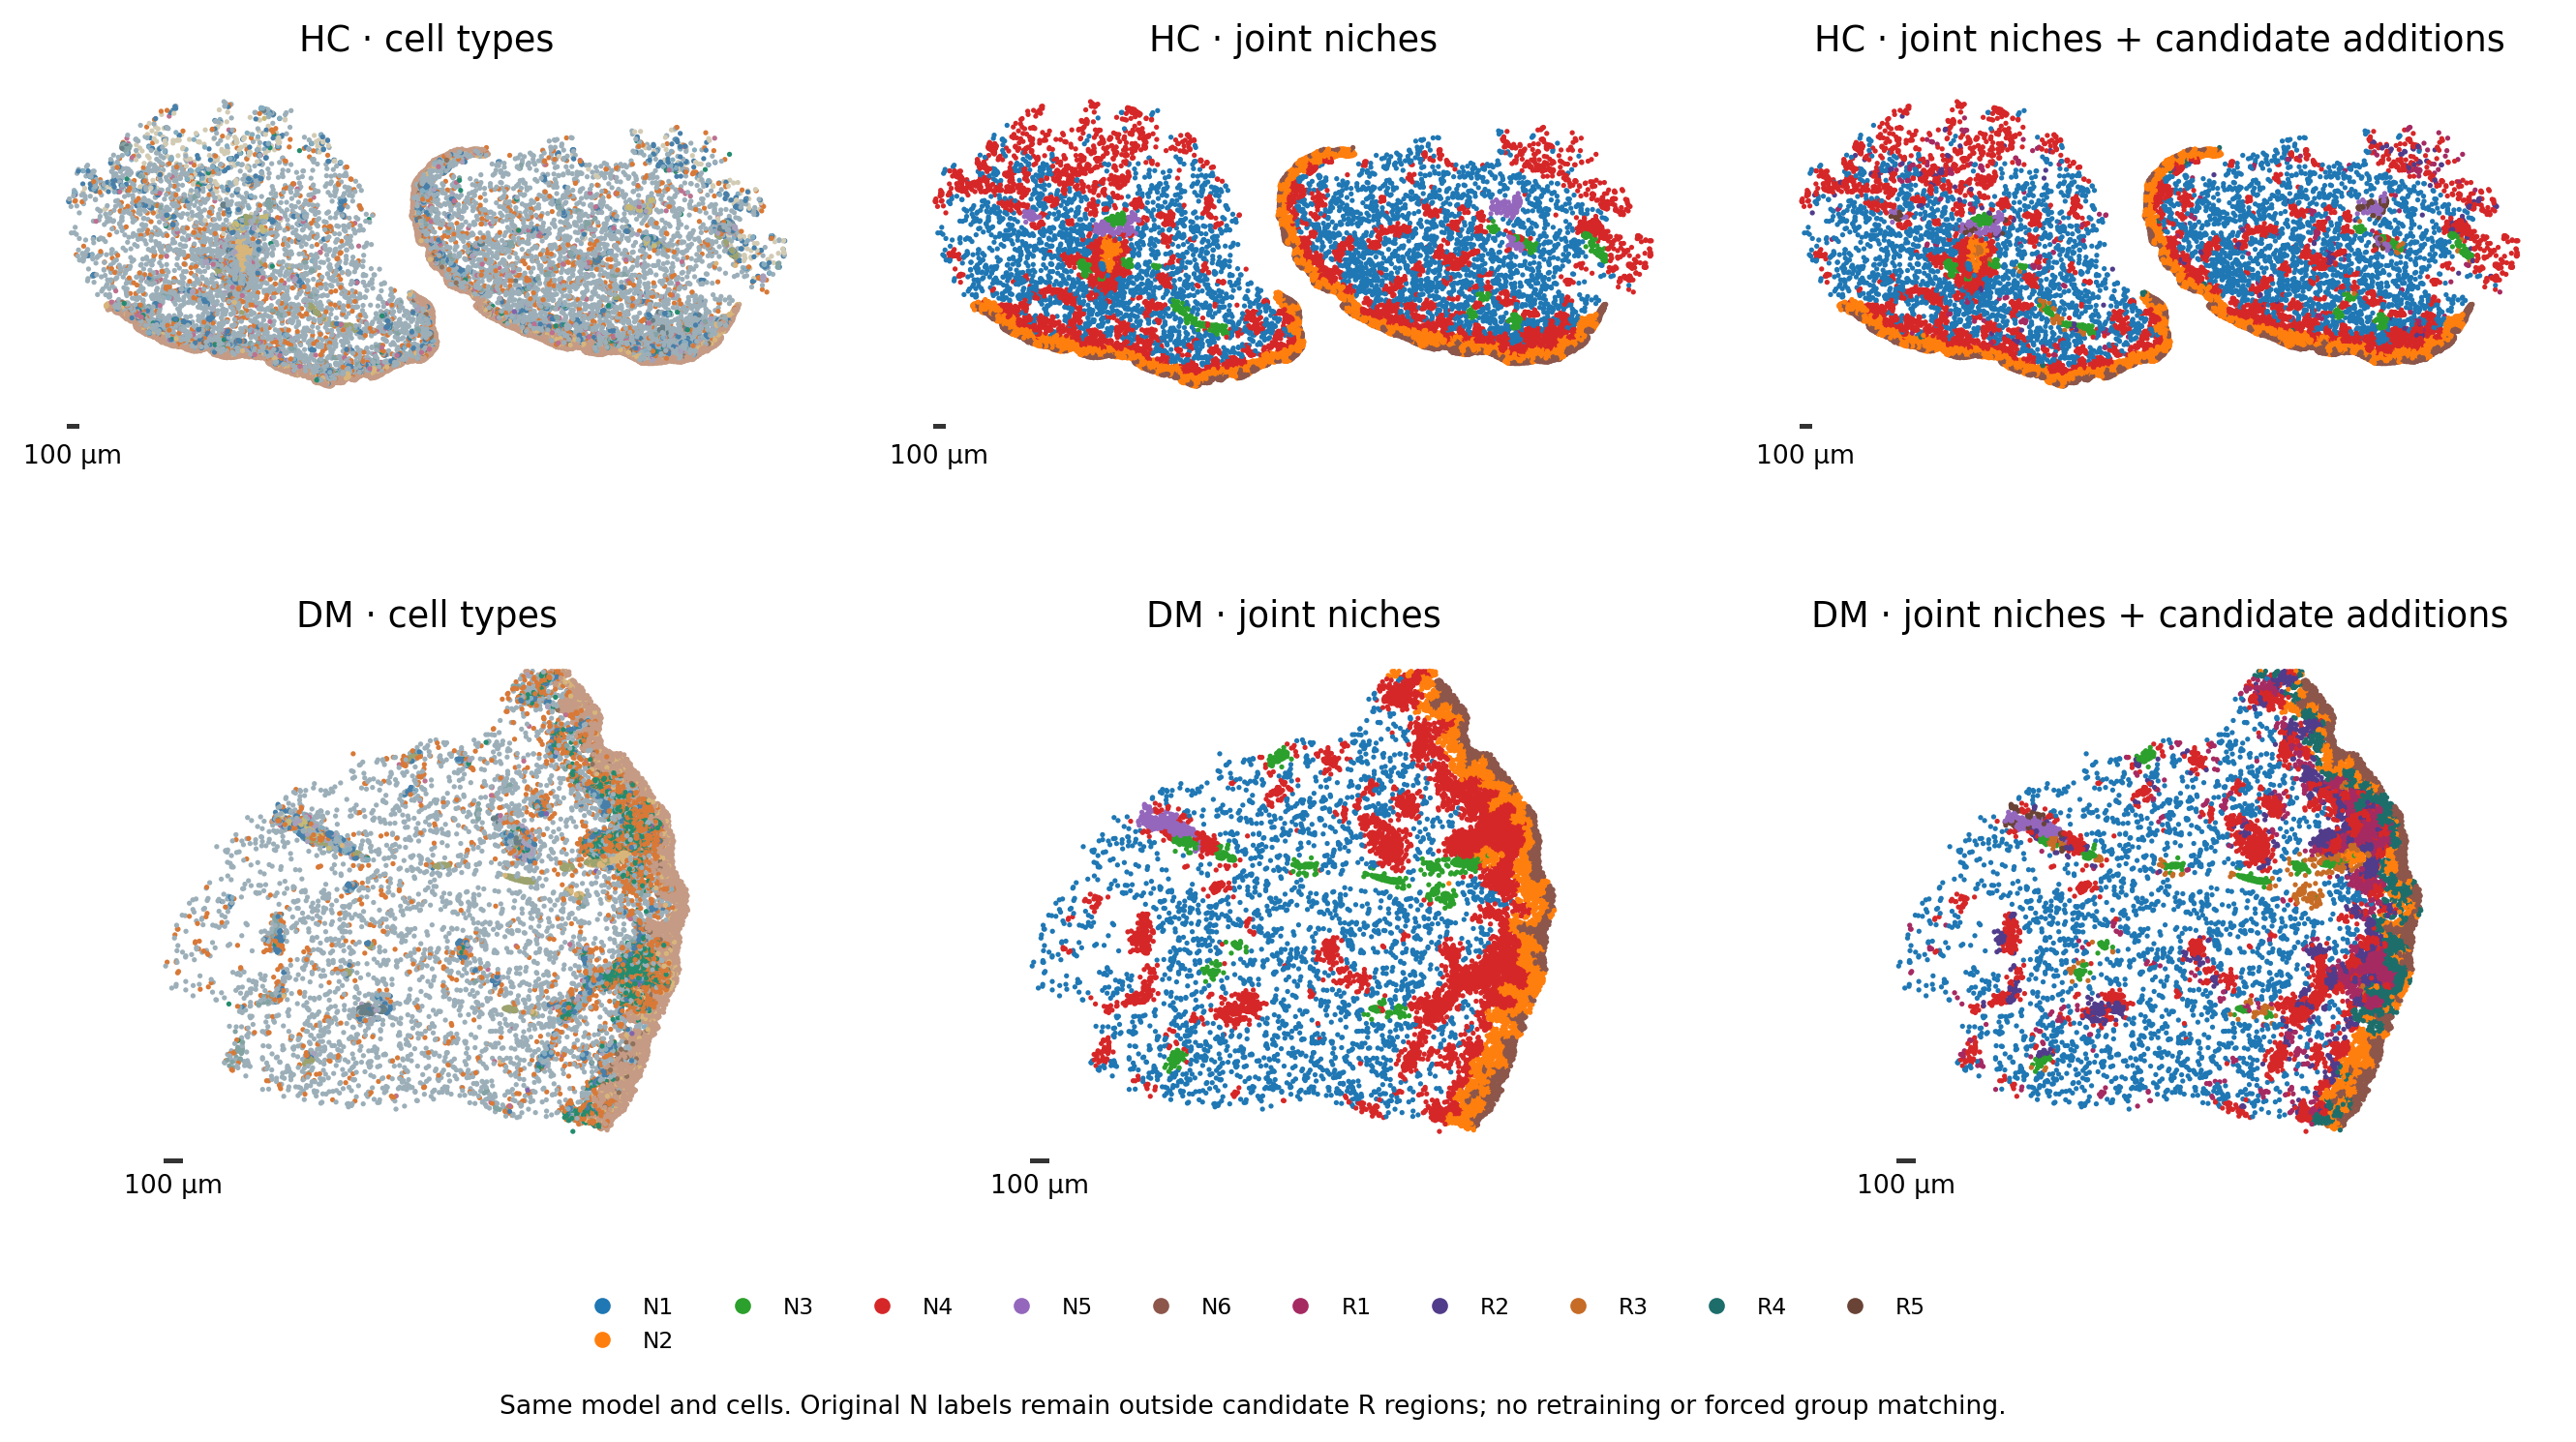

Results: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/dermatomyositis_paper_guided/H8_DM21


In [8]:
show(report.comparison())
print('Results:',OUTPUT)